installing SHAP

In [ ]:
%pip install shap


In [1]:
import joblib
import os

model_path = "models/xgboost_predictive_maintenance.pkl"

if os.path.exists(model_path):
    final_model = joblib.load(model_path)
    print("XGBoost model loaded successfully!")
else:
    print("Model file not found:", model_path)

XGBoost model loaded successfully!


In [2]:
print("Pipeline steps:")

for name, step in final_model.named_steps.items():
    print(name, ":", type(step).__name__)

Pipeline steps:
preprocessing : ColumnTransformer
classifier : XGBClassifier


In [4]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

print("SHAP version:", shap.__version__)
print("Libraries imported successfully!")

SHAP version: 0.54.1
Libraries imported successfully!


loading the dataset 

In [8]:
df = pd.read_csv("data/process_data.csv")

feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target_column = "Machine failure"

X = df[feature_columns]
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset loaded:", df.shape)
print("Test features:", X_test.shape)
print("Test target:", y_test.shape)

Dataset loaded: (10000, 14)
Test features: (2000, 6)
Test target: (2000,)


In [9]:
preprocessor = final_model.named_steps["preprocessing"]
xgb_classifier = final_model.named_steps["classifier"]

print("Preprocessor:", type(preprocessor).__name__)
print("Classifier:", type(xgb_classifier).__name__)

Preprocessor: ColumnTransformer
Classifier: XGBClassifier


transforming the testing data 

In [10]:
X_test_transformed = preprocessor.transform(X_test)

# Convert sparse matrix to dense if necessary
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

X_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("Transformed test data:", X_test_transformed.shape)
print("\nFeatures:")
print(list(feature_names))

Transformed test data: (2000, 8)

Features:
['num__Air temperature [K]', 'num__Process temperature [K]', 'num__Rotational speed [rpm]', 'num__Torque [Nm]', 'num__Tool wear [min]', 'cat__Type_H', 'cat__Type_L', 'cat__Type_M']


renaming the features 

In [13]:
import re

# Clean feature names for XGBoost compatibility
clean_feature_names = [
    re.sub(r"[\[\]<>]", "_", str(name))
    for name in feature_names
]

# Remove any duplicate names if present
seen = {}
unique_feature_names = []

for name in clean_feature_names:
    count = seen.get(name, 0)
    unique_name = name if count == 0 else f"{name}_{count}"
    unique_feature_names.append(unique_name)
    seen[name] = count + 1

# Update transformed dataframe columns
X_test_transformed.columns = unique_feature_names

print("Cleaned feature names:")
print(list(X_test_transformed.columns))

Cleaned feature names:
['num__Air temperature _K_', 'num__Process temperature _K_', 'num__Rotational speed _rpm_', 'num__Torque _Nm_', 'num__Tool wear _min_', 'cat__Type_H', 'cat__Type_L', 'cat__Type_M']


Calculating SHAP valuse

In [14]:
# Select a sample for explainability
X_explain = X_test_transformed.sample(
    n=min(300, len(X_test_transformed)),
    random_state=42
)

# Create TreeExplainer
explainer = shap.TreeExplainer(xgb_classifier)

# Calculate SHAP values
shap_values = explainer(X_explain)

print("SHAP values calculated successfully!")
print("SHAP output shape:", shap_values.values.shape)

SHAP values calculated successfully!
SHAP output shape: (300, 8)


SHAP summry plot 

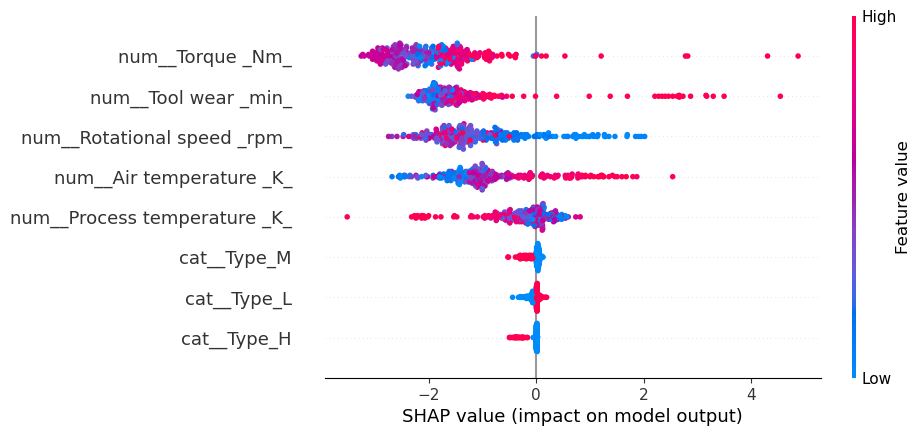

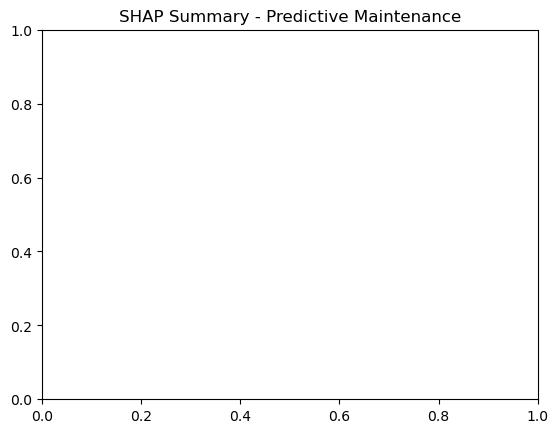

In [15]:
shap.plots.beeswarm(
    shap_values,
    max_display=10
)

plt.title("SHAP Summary - Predictive Maintenance")
plt.show()

feature importance

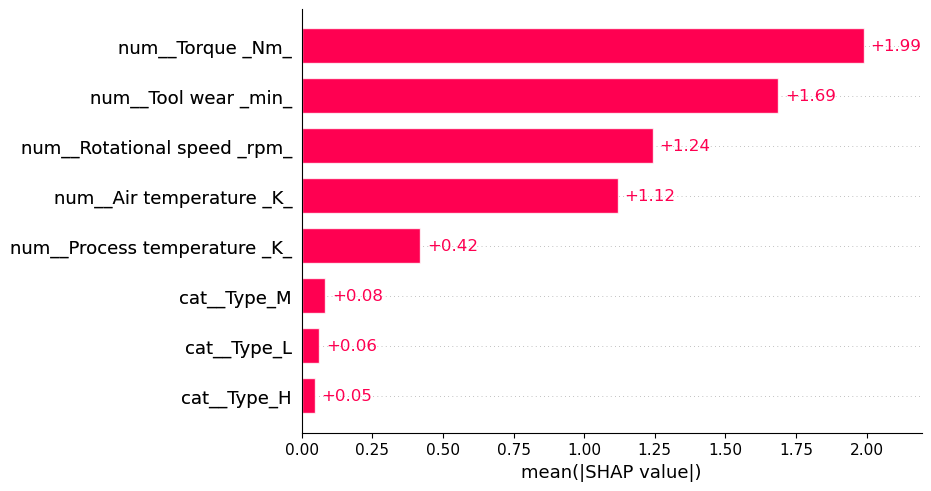

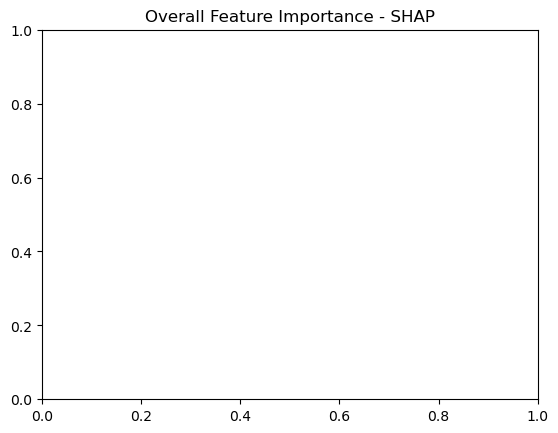

In [16]:
shap.plots.bar(
    shap_values,
    max_display=10
)

plt.title("Overall Feature Importance - SHAP")
plt.show()

loading thresold 

In [22]:
import joblib

best_threshold = joblib.load(
    "models/xgboost_threshold.pkl"
)

print("Loaded threshold:", best_threshold)

Loaded threshold: 0.7593754


local explainability 

In [23]:
# Select the original machine record
sample_index = X_explain.index[0]

# Get original input features
sample_machine = X_test.loc[[sample_index]]

# Get transformed input for SHAP
sample_machine_transformed = X_explain.loc[[sample_index]]

# Predict failure probability using complete pipeline
failure_probability = final_model.predict_proba(
    sample_machine
)[0][1]

# Apply selected threshold
prediction = int(failure_probability >= best_threshold)

print("Original machine features:")
display(sample_machine)

print("\nFailure probability:", round(failure_probability, 4))
print("Classification threshold:", best_threshold)

if prediction == 1:
    print("Prediction: Machine Failure")
else:
    print("Prediction: No Machine Failure")

Original machine features:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
4701,H,303.5,311.7,1584,32.7,143



Failure probability: 0.005
Classification threshold: 0.7593754
Prediction: No Machine Failure


local SHAP expaination

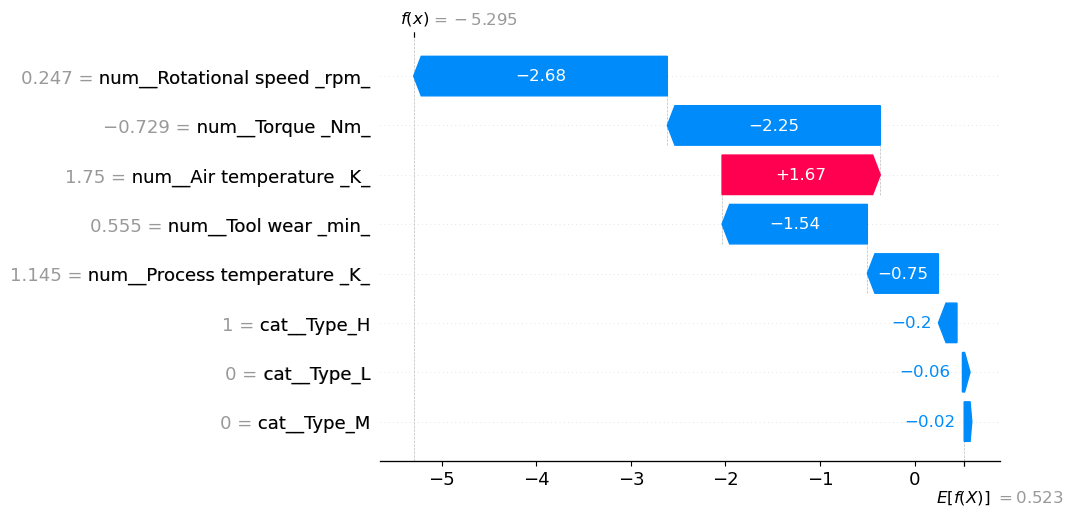

In [24]:
shap.plots.waterfall(
    shap_values[0],
    max_display=10
)

In [25]:
print("SHAP values shape:", shap_values.values.shape)
print("Explanation data shape:", X_explain.shape)
print("Feature names:")
print(list(X_explain.columns))

SHAP values shape: (300, 8)
Explanation data shape: (300, 8)
Feature names:
['num__Air temperature _K_', 'num__Process temperature _K_', 'num__Rotational speed _rpm_', 'num__Torque _Nm_', 'num__Tool wear _min_', 'cat__Type_H', 'cat__Type_L', 'cat__Type_M']


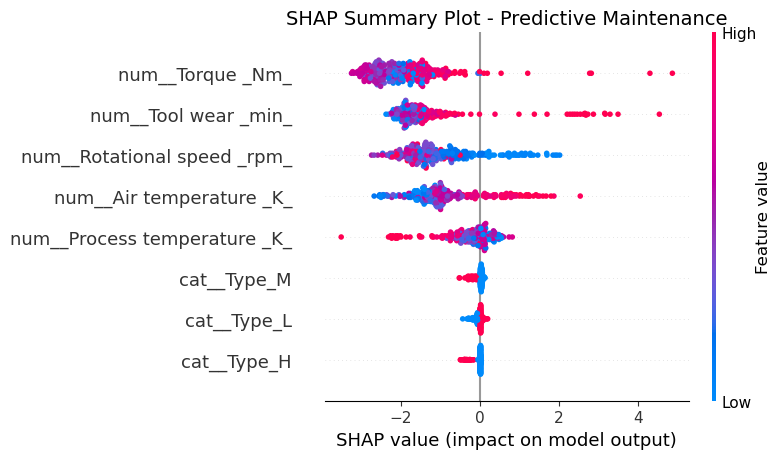

In [26]:
import shap
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

shap.plots.beeswarm(
    shap_values,
    max_display=10,
    show=False
)

plt.title(
    "SHAP Summary Plot - Predictive Maintenance",
    fontsize=14
)

plt.tight_layout()
plt.show()

global features importance

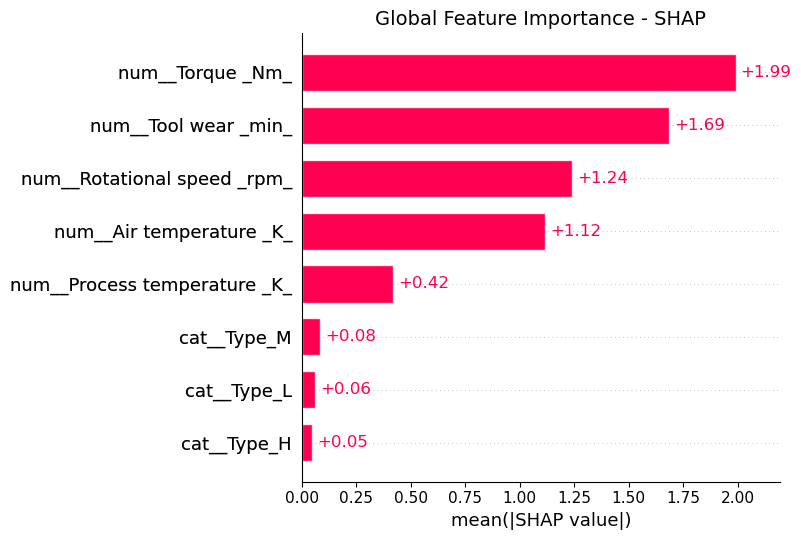

In [27]:
plt.figure(figsize=(10, 6))

shap.plots.bar(
    shap_values,
    max_display=10,
    show=False
)

plt.title(
    "Global Feature Importance - SHAP",
    fontsize=14
)

plt.tight_layout()
plt.show()

SHAP dependence plot

Dependence plot: num__Torque _Nm_


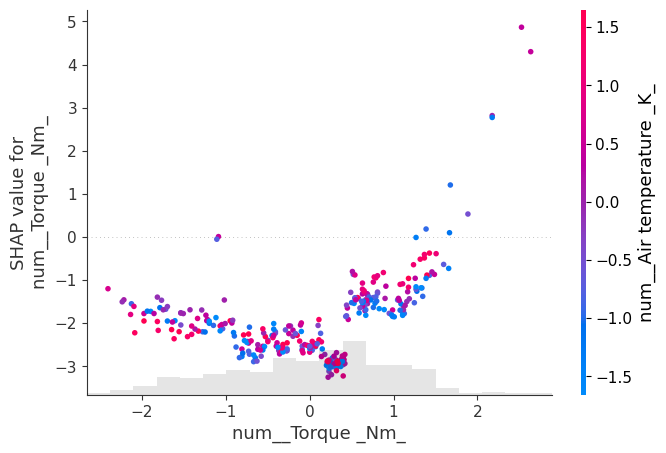

Dependence plot: num__Tool wear _min_


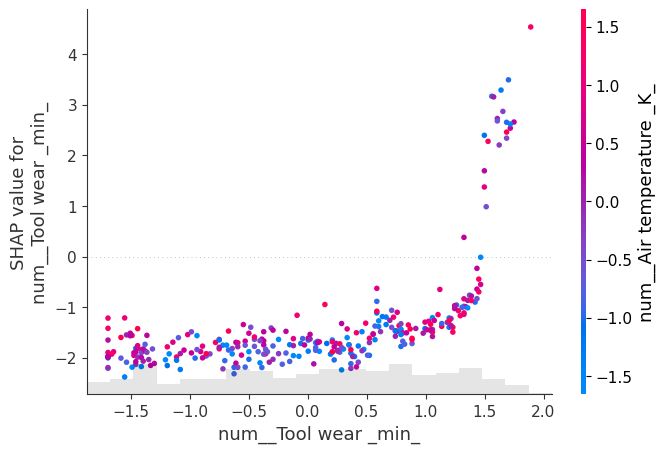

Dependence plot: num__Rotational speed _rpm_


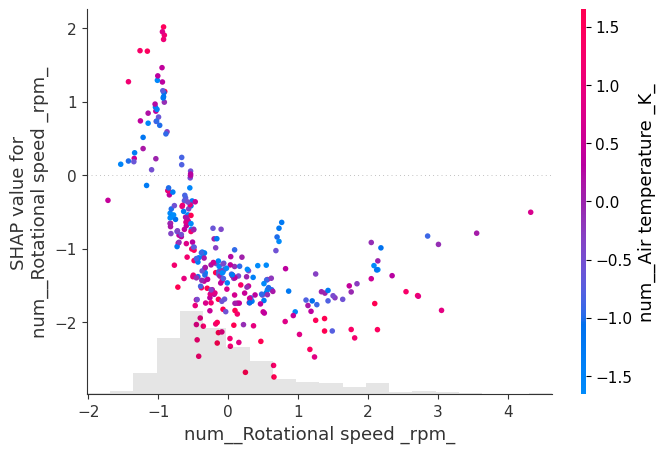

In [28]:
# Select important features from global SHAP values
top_features = (
    shap_values.abs
    .mean(0)
    .values
)

top_feature_indices = top_features.argsort()[-3:][::-1]

for index in top_feature_indices:

    feature_name = X_explain.columns[index]

    print("Dependence plot:", feature_name)

    shap.plots.scatter(
        shap_values[:, feature_name],
        color=shap_values,
        show=True
    )

global SHAP bar chart

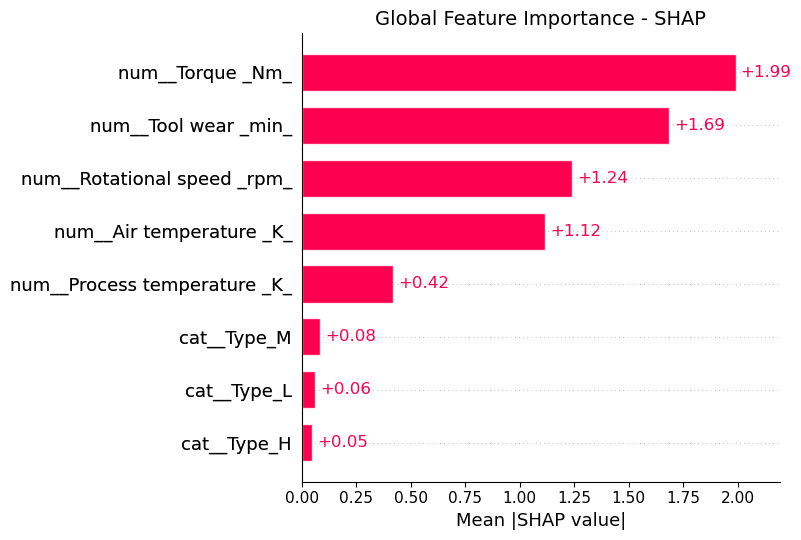

In [29]:
import matplotlib.pyplot as plt
import shap

plt.figure(figsize=(10, 6))

shap.plots.bar(
    shap_values,
    max_display=10,
    show=False
)

plt.title("Global Feature Importance - SHAP", fontsize=14)
plt.xlabel("Mean |SHAP value|")
plt.tight_layout()
plt.show()

SHAP Heatmamp 

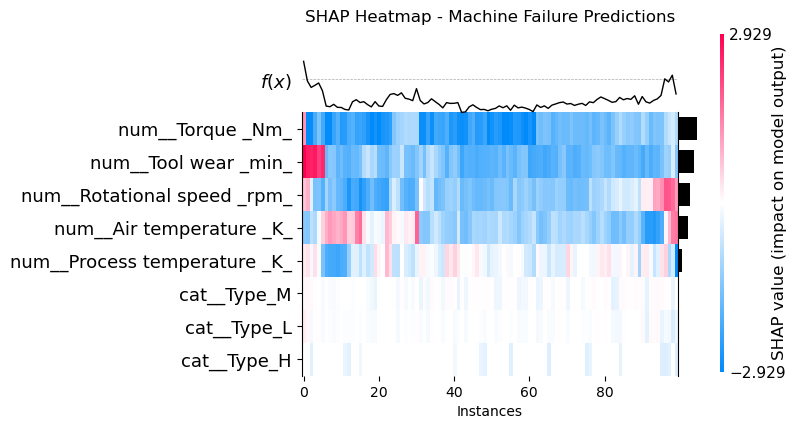

In [30]:
import matplotlib.pyplot as plt
import shap

plt.figure(figsize=(12, 7))

shap.plots.heatmap(
    shap_values[:100],
    max_display=8,
    show=False
)

plt.title("SHAP Heatmap - Machine Failure Predictions")
plt.tight_layout()
plt.show()